# AR Behavioural Biometrics — Analysis

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

assert sklearn.__version__ == "1.8.0", (
    f"Expected scikit-learn 1.8.0, found {sklearn.__version__}"
)

DATA_DIR = Path(".")
DEV_FILE = DATA_DIR / r"C:\Users\Onyeka\Downloads\InteractionEvents-Dataset.csv"
LATER_FILE = DATA_DIR / r"C:\Users\Onyeka\Downloads\InteractionEvents-Prediction-UnseenData-Dataset.csv"

OUTPUT_DIR = Path("analysis_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

RATE_HZ = 5.0
DT = 1.0 / RATE_HZ
WINDOW_SECONDS = 3.0
STEPS_PER_WINDOW = int(RATE_HZ * WINDOW_SECONDS)
TIME_COL = "RelativeTime"

RETURNING_USERS = [1, 2, 13, 54, 55]
FIXED_NON_ENROLLED = list(range(39, 54))
FIXED_ENROLLED = list(range(1, 39)) + [54, 55]

EXTRATREES_SEEDS = [42, 43, 44, 45, 46]
PARTITION_SEEDS = list(range(100, 110))
BOOTSTRAP_SEED = 4242
N_BOOTSTRAP = 5000

GAZE_FEATURES = [
    "Duration",
    "InteractionInterval",
    "GazeDirX", "GazeDirY", "GazeDirZ",
    "DistanceToObject",
]

HEAD_FEATURES = [
    "HeadPosX", "HeadPosY", "HeadPosZ",
    "HeadRotX", "HeadRotY", "HeadRotZ", "HeadRotW",
    "HeadVelocity",
]

HAND_FEATURES = [
    "LeftHandPosX", "LeftHandPosY", "LeftHandPosZ",
    "RightHandPosX", "RightHandPosY", "RightHandPosZ",
    "LeftHandVelocity", "RightHandVelocity",
]

FEATURE_SET = set(GAZE_FEATURES + HEAD_FEATURES + HAND_FEATURES)

DYNAMIC_ONLY_SET = {
    "Duration", "InteractionInterval",
    "GazeDirX", "GazeDirY", "GazeDirZ",
    "HeadRotX", "HeadRotY", "HeadRotZ", "HeadRotW",
    "HeadVelocity",
    "LeftHandVelocity", "RightHandVelocity",
}

Python: 3.11.17
NumPy: 2.4.6
pandas: 3.0.6
scikit-learn: 1.8.0


## Load data

In [2]:
assert DEV_FILE.exists(), f"Missing file: {DEV_FILE}"
assert LATER_FILE.exists(), f"Missing file: {LATER_FILE}"

dev_raw = pd.read_csv(DEV_FILE)
later_raw = pd.read_csv(LATER_FILE)

# Use original CSV column order for the archived numeric feature set.
ALL_FEATURES = [c for c in dev_raw.columns if c in FEATURE_SET]

GAZE_FEATURES_CSV = [c for c in ALL_FEATURES if c in set(GAZE_FEATURES)]
HEAD_FEATURES_CSV = [c for c in ALL_FEATURES if c in set(HEAD_FEATURES)]
HAND_FEATURES_CSV = [c for c in ALL_FEATURES if c in set(HAND_FEATURES)]
DYNAMIC_ONLY_FEATURES = [c for c in ALL_FEATURES if c in DYNAMIC_ONLY_SET]

MODALITY_CONFIGS = {
    "Gaze only": GAZE_FEATURES_CSV,
    "Head only": HEAD_FEATURES_CSV,
    "Hand only": HAND_FEATURES_CSV,
    "Gaze + Head": [c for c in ALL_FEATURES if c in set(GAZE_FEATURES + HEAD_FEATURES)],
    "Gaze + Hand": [c for c in ALL_FEATURES if c in set(GAZE_FEATURES + HAND_FEATURES)],
    "Head + Hand": [c for c in ALL_FEATURES if c in set(HEAD_FEATURES + HAND_FEATURES)],
    "All modalities": ALL_FEATURES,
}

required = {"SessionID", "UserID", "StepIndex", TIME_COL, *ALL_FEATURES}

missing_dev = sorted(required - set(dev_raw.columns))
missing_later = sorted(required - set(later_raw.columns))

assert not missing_dev, f"Missing development columns: {missing_dev}"
assert not missing_later, f"Missing later-session columns: {missing_later}"

dataset_summary = pd.DataFrame([
    {
        "Dataset": "Development",
        "Rows": len(dev_raw),
        "Columns": len(dev_raw.columns),
        "Users": dev_raw["UserID"].nunique(),
        "Sessions": dev_raw["SessionID"].nunique(),
    },
    {
        "Dataset": "Later session",
        "Rows": len(later_raw),
        "Columns": len(later_raw.columns),
        "Users": later_raw["UserID"].nunique(),
        "Sessions": later_raw["SessionID"].nunique(),
    },
])

display(dataset_summary)

print("Feature order:")
print(ALL_FEATURES)

,Dataset,Rows,Columns,Users,Sessions
0,Development,10030,43,55,74
1,Later session,1965,43,5,14


Feature order:
['Duration', 'InteractionInterval', 'HeadPosX', 'HeadPosY', 'HeadPosZ', 'HeadRotX', 'HeadRotY', 'HeadRotZ', 'HeadRotW', 'LeftHandPosX', 'LeftHandPosY', 'LeftHandPosZ', 'RightHandPosX', 'RightHandPosY', 'RightHandPosZ', 'GazeDirX', 'GazeDirY', 'GazeDirZ', 'DistanceToObject', 'HeadVelocity', 'LeftHandVelocity', 'RightHandVelocity']


## Remove overlapping session

In [3]:
overlap_sessions = sorted(
    set(dev_raw["SessionID"].dropna().unique())
    & set(later_raw["SessionID"].dropna().unique())
)

common_cols = [c for c in dev_raw.columns if c in later_raw.columns]

duplicate_rows = 0
if overlap_sessions:
    dev_overlap = dev_raw[dev_raw["SessionID"].isin(overlap_sessions)][common_cols]
    later_overlap = later_raw[later_raw["SessionID"].isin(overlap_sessions)][common_cols]

    dev_index = pd.MultiIndex.from_frame(dev_overlap)
    later_index = pd.MultiIndex.from_frame(later_overlap)

    duplicate_rows = int(later_index.isin(dev_index).sum())

later_clean = later_raw[
    ~later_raw["SessionID"].isin(overlap_sessions)
].copy()

audit = pd.DataFrame([{
    "OverlappingSessionIDs": ",".join(map(str, overlap_sessions)),
    "ExactDuplicatedRows": duplicate_rows,
    "LaterRowsBefore": len(later_raw),
    "LaterRowsAfter": len(later_clean),
    "LaterSessionsAfter": later_clean["SessionID"].nunique(),
}])

display(audit)

assert overlap_sessions == [5077]
assert duplicate_rows == 144
assert len(later_clean) == 1820
assert later_clean["SessionID"].nunique() == 13

,OverlappingSessionIDs,ExactDuplicatedRows,LaterRowsBefore,LaterRowsAfter,LaterSessionsAfter
0,5077,144,1965,1820,13


## Resample and window

In [4]:
def _interp_channel(t, values, grid):
    v = pd.to_numeric(
        pd.Series(values),
        errors="coerce",
    ).to_numpy(dtype=float)

    good = np.isfinite(t) & np.isfinite(v)

    if good.sum() == 0:
        return np.zeros(len(grid), dtype=float)

    if good.sum() == 1:
        return np.full(len(grid), v[good][0], dtype=float)

    return np.interp(grid, t[good], v[good])


def resample_stream(group, feature_cols):
    g = group[[TIME_COL] + list(feature_cols)].copy()

    g[TIME_COL] = pd.to_numeric(
        g[TIME_COL],
        errors="coerce",
    )

    g = g.dropna(subset=[TIME_COL])

    for c in feature_cols:
        g[c] = pd.to_numeric(
            g[c],
            errors="coerce",
        )

    if len(g) < 2:
        return None, None

    agg = (
        g.groupby(TIME_COL, sort=True)[list(feature_cols)]
        .mean()
    )

    t = agg.index.to_numpy(dtype=float)

    if (
        len(t) < 2
        or not np.isfinite(t).all()
        or t[-1] <= t[0]
    ):
        return None, None

    # 5 Hz grid anchored at the first timestamp of each stream.
    # The last recorded timestamp is an exclusive boundary.
    start = float(t[0])
    stop = float(t[-1])
    tolerance = 1e-10

    n_grid = int(
        np.ceil(
            (stop - start) / DT - tolerance
        )
    )

    if n_grid <= 0:
        return None, None

    grid = start + np.arange(
        n_grid,
        dtype=float,
    ) * DT

    grid = grid[
        grid < stop - tolerance
    ]

    if len(grid) < STEPS_PER_WINDOW:
        return None, None

    data = np.column_stack([
        _interp_channel(
            t,
            agg[c].to_numpy(),
            grid,
        )
        for c in feature_cols
    ])

    return grid, data


def build_windows(df, feature_cols):
    windows = []
    metadata = []

    for (uid, sid), group in df.groupby(
        ["UserID", "SessionID"],
        sort=True,
    ):
        grid, data = resample_stream(
            group,
            feature_cols,
        )

        if grid is None:
            continue

        n_windows = len(data) // STEPS_PER_WINDOW

        for w in range(n_windows):
            a = w * STEPS_PER_WINDOW
            b = a + STEPS_PER_WINDOW

            windows.append(data[a:b])

            metadata.append({
                "UserID": int(uid),
                "SessionID": sid,
                "WindowStart": float(grid[a]),
                "WindowEnd": float(grid[b - 1]),
            })

    if not windows:
        return (
            np.empty(
                (0, STEPS_PER_WINDOW, len(feature_cols)),
                dtype=float,
            ),
            pd.DataFrame(metadata),
        )

    return np.stack(windows), pd.DataFrame(metadata)


X_dev_all, meta_dev_all = build_windows(
    dev_raw,
    ALL_FEATURES,
)

X_later_all, meta_later_all = build_windows(
    later_clean,
    ALL_FEATURES,
)

enrolled_mask = meta_dev_all["UserID"].isin(
    FIXED_ENROLLED
).to_numpy()

unknown_mask = meta_dev_all["UserID"].isin(
    FIXED_NON_ENROLLED
).to_numpy()

window_summary = pd.DataFrame([{
    "DevelopmentWindows": len(meta_dev_all),
    "FixedEnrolledWindows": int(enrolled_mask.sum()),
    "FixedNonEnrolledWindows": int(unknown_mask.sum()),
    "LaterSessionWindows": len(meta_later_all),
}])

display(window_summary)

assert len(meta_dev_all) == 9251
assert int(enrolled_mask.sum()) == 6743
assert int(unknown_mask.sum()) == 2508
assert len(meta_later_all) == 926

,DevelopmentWindows,FixedEnrolledWindows,FixedNonEnrolledWindows,LaterSessionWindows
0,9251,6743,2508,926


## Chronological split

In [5]:
def chronological_block_indices(
    meta,
    eligible_mask,
    train_fraction=0.80,
):
    train_idx = []
    val_idx = []

    eligible = meta.loc[
        np.asarray(eligible_mask, dtype=bool)
    ].copy()

    for _, grp in eligible.groupby(
        ["UserID", "SessionID"],
        sort=True,
    ):
        ids = (
            grp.sort_values("WindowStart")
            .index
            .to_numpy()
        )

        n = len(ids)

        if n == 1:
            train_idx.extend(ids)
            continue

        # Nearest-integer 80/20 split within each user-session stream.
        cut = int(
            np.floor(
                train_fraction * n + 0.5
            )
        )

        cut = max(
            1,
            min(cut, n - 1),
        )

        train_idx.extend(ids[:cut])
        val_idx.extend(ids[cut:])

    return (
        np.asarray(train_idx, dtype=int),
        np.asarray(val_idx, dtype=int),
    )


fixed_train_idx, fixed_val_idx = chronological_block_indices(
    meta_dev_all,
    enrolled_mask,
)

y_dev = meta_dev_all["UserID"].to_numpy(dtype=int)
y_later = meta_later_all["UserID"].to_numpy(dtype=int)

y_train_fixed = y_dev[fixed_train_idx]
y_val_fixed = y_dev[fixed_val_idx]

split_summary = pd.DataFrame([{
    "TrainingWindows": len(fixed_train_idx),
    "ValidationWindows": len(fixed_val_idx),
}])

display(split_summary)

assert len(fixed_train_idx) == 5395
assert len(fixed_val_idx) == 1348

,TrainingWindows,ValidationWindows
0,5395,1348


## ExtraTrees utilities

In [9]:
FEATURE_INDEX = {
    name: i
    for i, name in enumerate(ALL_FEATURES)
}


def select_flatten(X, feature_names):
    idx = [
        FEATURE_INDEX[c]
        for c in feature_names
    ]

    # Time-major flattening.
    return X[:, :, idx].reshape(
        len(X),
        -1,
    )


def fit_standardizer(X_train):
    mean = np.nanmean(
        X_train,
        axis=0,
    )

    std = np.nanstd(
        X_train,
        axis=0,
    )

    mean = np.where(
        np.isfinite(mean),
        mean,
        0.0,
    )

    std = np.where(
        np.isfinite(std) & (std >= 1e-9),
        std,
        1.0,
    )

    return mean, std


def apply_standardizer(X, mean, std):
    Z = (X - mean) / std

    return np.nan_to_num(
        Z,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    )


def make_extratrees(seed):
    return ExtraTreesClassifier(
        n_estimators=400,
        criterion="gini",
        max_features="sqrt",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        bootstrap=False,
        class_weight=None,
        random_state=seed,
        n_jobs=-1,
    )


def balanced_accuracy_present_classes(
    y_true,
    y_pred,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    recalls = []

    for cls in np.unique(y_true):
        mask = (y_true == cls)

        recalls.append(
            np.mean(
                y_pred[mask] == cls
            )
        )

    return float(
        np.mean(recalls)
    )


def prepare_fixed_feature_set(
    feature_names,
):
    X_dev = select_flatten(
        X_dev_all,
        feature_names,
    )

    X_later = select_flatten(
        X_later_all,
        feature_names,
    )

    X_train = X_dev[
        fixed_train_idx
    ]

    X_val = X_dev[
        fixed_val_idx
    ]

    X_unknown = X_dev[
        unknown_mask
    ]

    mean, std = fit_standardizer(
        X_train
    )

    return {
        "train": apply_standardizer(
            X_train,
            mean,
            std,
        ),
        "val": apply_standardizer(
            X_val,
            mean,
            std,
        ),
        "unknown": apply_standardizer(
            X_unknown,
            mean,
            std,
        ),
        "later": apply_standardizer(
            X_later,
            mean,
            std,
        ),
        "mean": mean,
        "std": std,
    }

## Modality ablation

In [10]:
ablation_rows = []

for name, features in MODALITY_CONFIGS.items():
    prepared = prepare_fixed_feature_set(
        features
    )

    for seed in EXTRATREES_SEEDS:
        model = make_extratrees(
            seed
        )

        model.fit(
            prepared["train"],
            y_train_fixed,
        )

        pred_val = model.predict(
            prepared["val"]
        )

        pred_later = model.predict(
            prepared["later"]
        )

        ablation_rows.append({
            "Input": name,
            "Seed": seed,
            "BlockedIntraAccuracy":
                accuracy_score(
                    y_val_fixed,
                    pred_val,
                ),
            "CrossSessionAccuracy":
                accuracy_score(
                    y_later,
                    pred_later,
                ),
            "CrossSessionBalancedAccuracy":
                balanced_accuracy_present_classes(
                    y_later,
                    pred_later,
                ),
        })


ablation_runs = pd.DataFrame(
    ablation_rows
)

ablation_summary = (
    ablation_runs
    .groupby(
        "Input",
        sort=False,
    )
    .agg(
        BlockedIntraAccuracy_mean=(
            "BlockedIntraAccuracy",
            "mean",
        ),
        BlockedIntraAccuracy_sd=(
            "BlockedIntraAccuracy",
            "std",
        ),
        CrossSessionAccuracy_mean=(
            "CrossSessionAccuracy",
            "mean",
        ),
        CrossSessionAccuracy_sd=(
            "CrossSessionAccuracy",
            "std",
        ),
        CrossSessionBalancedAccuracy_mean=(
            "CrossSessionBalancedAccuracy",
            "mean",
        ),
        CrossSessionBalancedAccuracy_sd=(
            "CrossSessionBalancedAccuracy",
            "std",
        ),
    )
    .reset_index()
)

ablation_display = (
    ablation_summary.copy()
)

for c in ablation_display.columns[1:]:
    ablation_display[c] = (
        100 * ablation_display[c]
    )

display(
    ablation_display.round(2)
)

ablation_runs.to_csv(
    OUTPUT_DIR / "modality_ablation_runs.csv",
    index=False,
)

ablation_summary.to_csv(
    OUTPUT_DIR / "modality_ablation_summary.csv",
    index=False,
)

,Input,BlockedIntraAccuracy_mean,BlockedIntraAccuracy_sd,CrossSessionAccuracy_mean,CrossSessionAccuracy_sd,CrossSessionBalancedAccuracy_mean,CrossSessionBalancedAccuracy_sd
0,Gaze only,16.29,0.24,10.86,0.43,11.52,0.39
1,Head only,46.13,0.51,23.39,0.75,23.54,0.98
2,Hand only,22.26,0.54,30.39,0.48,23.75,0.46
3,Gaze + Head,48.38,0.67,30.78,1.36,31.10,1.18
4,Gaze + Hand,29.51,0.46,29.91,0.44,28.30,0.37
5,Head + Hand,51.28,0.43,40.86,0.33,37.71,0.51
6,All modalities,52.48,0.47,43.39,1.22,41.23,1.36


## Random-window comparison and majority baselines

In [11]:
X_fixed_all = select_flatten(
    X_dev_all[enrolled_mask],
    ALL_FEATURES,
)

y_fixed_all = y_dev[
    enrolled_mask
]

idx = np.arange(
    len(y_fixed_all)
)

rnd_train, rnd_val = train_test_split(
    idx,
    test_size=0.20,
    random_state=42,
    stratify=y_fixed_all,
)

rnd_mean, rnd_std = fit_standardizer(
    X_fixed_all[rnd_train]
)

X_rnd_train = apply_standardizer(
    X_fixed_all[rnd_train],
    rnd_mean,
    rnd_std,
)

X_rnd_val = apply_standardizer(
    X_fixed_all[rnd_val],
    rnd_mean,
    rnd_std,
)

rnd_model = make_extratrees(
    42
)

rnd_model.fit(
    X_rnd_train,
    y_fixed_all[rnd_train],
)

rnd_pred = rnd_model.predict(
    X_rnd_val
)

rnd_acc = accuracy_score(
    y_fixed_all[rnd_val],
    rnd_pred,
)


def majority_baseline(y):
    _, counts = np.unique(
        y,
        return_counts=True,
    )

    return counts.max() / counts.sum()


comparison_table = pd.DataFrame([
    {
        "Measure": "Random-window accuracy",
        "Value": rnd_acc,
    },
    {
        "Measure": "Blocked-validation majority baseline",
        "Value": majority_baseline(y_val_fixed),
    },
    {
        "Measure": "Later-session majority baseline",
        "Value": majority_baseline(y_later),
    },
])

comparison_table["Percent"] = (
    100 * comparison_table["Value"]
)

display(
    comparison_table[
        ["Measure", "Percent"]
    ].round(2)
)

comparison_table.to_csv(
    OUTPUT_DIR / "baseline_comparison.csv",
    index=False,
)

,Measure,Percent
0,Random-window accuracy,93.48
1,Blocked-validation majority baseline,10.39
2,Later-session majority baseline,30.35


## Dynamic-only ablation

In [12]:
dynamic_prepared = prepare_fixed_feature_set(
    DYNAMIC_ONLY_FEATURES
)

dynamic_rows = []

for seed in EXTRATREES_SEEDS:
    model = make_extratrees(
        seed
    )

    model.fit(
        dynamic_prepared["train"],
        y_train_fixed,
    )

    pred_val = model.predict(
        dynamic_prepared["val"]
    )

    pred_later = model.predict(
        dynamic_prepared["later"]
    )

    dynamic_rows.append({
        "Seed": seed,
        "BlockedIntraAccuracy":
            accuracy_score(
                y_val_fixed,
                pred_val,
            ),
        "CrossSessionAccuracy":
            accuracy_score(
                y_later,
                pred_later,
            ),
        "CrossSessionBalancedAccuracy":
            balanced_accuracy_present_classes(
                y_later,
                pred_later,
            ),
    })


dynamic_runs = pd.DataFrame(
    dynamic_rows
)

dynamic_summary = pd.DataFrame([{
    "BlockedIntraAccuracy_mean":
        dynamic_runs["BlockedIntraAccuracy"].mean(),
    "BlockedIntraAccuracy_sd":
        dynamic_runs["BlockedIntraAccuracy"].std(ddof=1),
    "CrossSessionAccuracy_mean":
        dynamic_runs["CrossSessionAccuracy"].mean(),
    "CrossSessionAccuracy_sd":
        dynamic_runs["CrossSessionAccuracy"].std(ddof=1),
    "CrossSessionBalancedAccuracy_mean":
        dynamic_runs["CrossSessionBalancedAccuracy"].mean(),
    "CrossSessionBalancedAccuracy_sd":
        dynamic_runs["CrossSessionBalancedAccuracy"].std(ddof=1),
}])

dynamic_display = (
    100 * dynamic_summary
)

display(
    dynamic_display.round(2)
)

dynamic_runs.to_csv(
    OUTPUT_DIR / "dynamic_only_runs.csv",
    index=False,
)

dynamic_summary.to_csv(
    OUTPUT_DIR / "dynamic_only_summary.csv",
    index=False,
)

,BlockedIntraAccuracy_mean,BlockedIntraAccuracy_sd,CrossSessionAccuracy_mean,CrossSessionAccuracy_sd,CrossSessionBalancedAccuracy_mean,CrossSessionBalancedAccuracy_sd
0,29.64,0.3,32.87,0.58,32.13,0.51


## Seed-42 model, bootstrap intervals and per-user recall

,Evaluation,Accuracy,CI_lower,CI_upper
0,Blocked intrasession,52.74,39.73,65.06
1,Cross-session,41.90,18.13,59.12


,UserID,Windows,Recall,RecallPercent
0,1,120,0.07,6.67
1,2,228,0.60,60.09
2,13,281,0.55,54.80
3,54,95,0.63,63.16
4,55,202,0.14,14.36


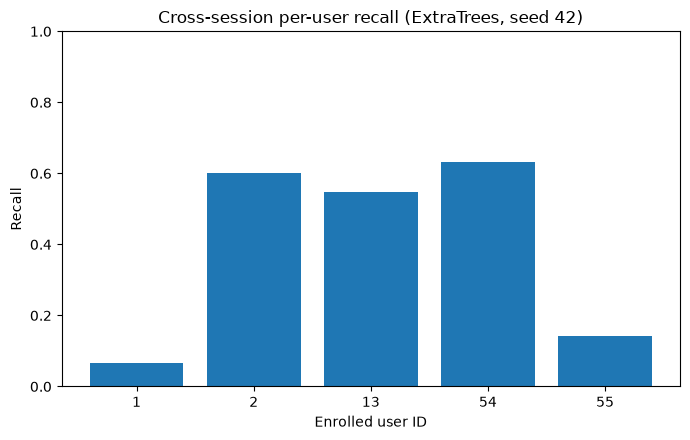

In [13]:
all_prepared = prepare_fixed_feature_set(
    ALL_FEATURES
)

model42 = make_extratrees(
    42
)

model42.fit(
    all_prepared["train"],
    y_train_fixed,
)

pred_val42 = model42.predict(
    all_prepared["val"]
)

pred_later42 = model42.predict(
    all_prepared["later"]
)


def participant_bootstrap_accuracy(
    y_true,
    y_pred,
    participant_ids,
    n_boot=5000,
    seed=4242,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    participant_ids = np.asarray(
        participant_ids
    )

    unique_ids = np.unique(
        participant_ids
    )

    by_user = {
        u: np.flatnonzero(
            participant_ids == u
        )
        for u in unique_ids
    }

    rng = np.random.default_rng(
        seed
    )

    values = np.empty(
        n_boot,
        dtype=float,
    )

    for b in range(n_boot):
        sampled_users = rng.choice(
            unique_ids,
            size=len(unique_ids),
            replace=True,
        )

        idx = np.concatenate([
            by_user[u]
            for u in sampled_users
        ])

        values[b] = accuracy_score(
            y_true[idx],
            y_pred[idx],
        )

    return (
        np.quantile(
            values,
            [0.025, 0.975],
        ),
        values,
    )


val_participants = (
    meta_dev_all.loc[
        fixed_val_idx,
        "UserID",
    ]
    .to_numpy(dtype=int)
)

later_participants = (
    meta_later_all["UserID"]
    .to_numpy(dtype=int)
)

val_ci, val_boot = (
    participant_bootstrap_accuracy(
        y_val_fixed,
        pred_val42,
        val_participants,
        N_BOOTSTRAP,
        BOOTSTRAP_SEED,
    )
)

later_ci, later_boot = (
    participant_bootstrap_accuracy(
        y_later,
        pred_later42,
        later_participants,
        N_BOOTSTRAP,
        BOOTSTRAP_SEED,
    )
)

bootstrap_table = pd.DataFrame([
    {
        "Evaluation": "Blocked intrasession",
        "Accuracy": accuracy_score(
            y_val_fixed,
            pred_val42,
        ),
        "CI_lower": val_ci[0],
        "CI_upper": val_ci[1],
    },
    {
        "Evaluation": "Cross-session",
        "Accuracy": accuracy_score(
            y_later,
            pred_later42,
        ),
        "CI_lower": later_ci[0],
        "CI_upper": later_ci[1],
    },
])

bootstrap_display = (
    bootstrap_table.copy()
)

for c in [
    "Accuracy",
    "CI_lower",
    "CI_upper",
]:
    bootstrap_display[c] = (
        100 * bootstrap_display[c]
    )

display(
    bootstrap_display.round(2)
)

bootstrap_table.to_csv(
    OUTPUT_DIR / "bootstrap_intervals_seed42.csv",
    index=False,
)


per_user_rows = []

for uid in RETURNING_USERS:
    mask = (
        y_later == uid
    )

    per_user_rows.append({
        "UserID": uid,
        "Windows": int(mask.sum()),
        "Recall": float(
            np.mean(
                pred_later42[mask] == uid
            )
        ),
    })

per_user = pd.DataFrame(
    per_user_rows
)

display(
    per_user.assign(
        RecallPercent=100 * per_user["Recall"]
    ).round(2)
)

per_user.to_csv(
    OUTPUT_DIR / "cross_session_per_user_recall_seed42.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(7, 4.5)
)

ax.bar(
    per_user["UserID"].astype(str),
    per_user["Recall"],
)

ax.set_ylim(0, 1)
ax.set_xlabel("Enrolled user ID")
ax.set_ylabel("Recall")
ax.set_title(
    "Cross-session per-user recall (ExtraTrees, seed 42)"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "cross_session_per_user_recall_baseline.pdf",
    bbox_inches="tight",
)

plt.show()

## Open-set utilities

In [14]:
def eer_from_scores(
    known_scores,
    unknown_scores,
):
    labels = np.r_[
        np.ones(
            len(known_scores),
            dtype=int,
        ),
        np.zeros(
            len(unknown_scores),
            dtype=int,
        ),
    ]

    scores = np.r_[
        known_scores,
        unknown_scores,
    ]

    fpr, tpr, thresholds = roc_curve(
        labels,
        scores,
        pos_label=1,
    )

    fnr = 1.0 - tpr

    i = np.nanargmin(
        np.abs(
            fpr - fnr
        )
    )

    eer = 0.5 * (
        fpr[i] + fnr[i]
    )

    return (
        float(eer),
        float(thresholds[i]),
    )


def oscr_curve_data(
    y_known,
    pred_known,
    known_scores,
    unknown_scores,
):
    y_known = np.asarray(y_known)
    pred_known = np.asarray(pred_known)
    known_scores = np.asarray(
        known_scores,
        dtype=float,
    )
    unknown_scores = np.asarray(
        unknown_scores,
        dtype=float,
    )

    correct_known = (
        pred_known == y_known
    )

    unique_scores = np.unique(
        np.r_[
            known_scores,
            unknown_scores,
        ]
    )

    thresholds = np.r_[
        np.inf,
        unique_scores[::-1],
        -np.inf,
    ]

    far = np.array([
        np.mean(
            unknown_scores >= t
        )
        for t in thresholds
    ])

    ccr = np.array([
        np.mean(
            correct_known
            & (known_scores >= t)
        )
        for t in thresholds
    ])

    return far, ccr, thresholds


def ccr_at_far(
    far,
    ccr,
    target_far,
):
    eligible = (
        far <= target_far + 1e-12
    )

    if not np.any(eligible):
        return 0.0

    return float(
        np.max(
            ccr[eligible]
        )
    )


def open_set_metrics(
    model,
    X_known,
    y_known,
    X_unknown,
):
    prob_known = model.predict_proba(
        X_known
    )

    prob_unknown = model.predict_proba(
        X_unknown
    )

    pred_known = model.classes_[
        np.argmax(
            prob_known,
            axis=1,
        )
    ]

    known_scores = np.max(
        prob_known,
        axis=1,
    )

    unknown_scores = np.max(
        prob_unknown,
        axis=1,
    )

    labels = np.r_[
        np.ones(
            len(known_scores),
            dtype=int,
        ),
        np.zeros(
            len(unknown_scores),
            dtype=int,
        ),
    ]

    scores = np.r_[
        known_scores,
        unknown_scores,
    ]

    auroc = roc_auc_score(
        labels,
        scores,
    )

    eer, eer_threshold = (
        eer_from_scores(
            known_scores,
            unknown_scores,
        )
    )

    far, ccr, thresholds = (
        oscr_curve_data(
            y_known,
            pred_known,
            known_scores,
            unknown_scores,
        )
    )

    return {
        "AUROC": float(auroc),
        "EER": float(eer),
        "EER_threshold": float(
            eer_threshold
        ),
        "CCR_at_5pct_FAR":
            ccr_at_far(
                far,
                ccr,
                0.05,
            ),
        "CCR_at_1pct_FAR":
            ccr_at_far(
                far,
                ccr,
                0.01,
            ),
        "known_scores":
            known_scores,
        "unknown_scores":
            unknown_scores,
        "pred_known":
            pred_known,
        "far":
            far,
        "ccr":
            ccr,
        "thresholds":
            thresholds,
    }

## Fixed 40/15 open-set analysis

In [15]:
fixed_open_rows = []
fixed_open_details = {}

for seed in EXTRATREES_SEEDS:
    model = make_extratrees(
        seed
    )

    model.fit(
        all_prepared["train"],
        y_train_fixed,
    )

    blocked = open_set_metrics(
        model,
        all_prepared["val"],
        y_val_fixed,
        all_prepared["unknown"],
    )

    later = open_set_metrics(
        model,
        all_prepared["later"],
        y_later,
        all_prepared["unknown"],
    )

    fixed_open_details[seed] = {
        "blocked": blocked,
        "later": later,
    }

    fixed_open_rows.extend([
        {
            "Seed": seed,
            "KnownSet":
                "Blocked intrasession",
            "AUROC":
                blocked["AUROC"],
            "EER":
                blocked["EER"],
            "CCR_at_5pct_FAR":
                blocked["CCR_at_5pct_FAR"],
            "CCR_at_1pct_FAR":
                blocked["CCR_at_1pct_FAR"],
        },
        {
            "Seed": seed,
            "KnownSet":
                "Cross-session",
            "AUROC":
                later["AUROC"],
            "EER":
                later["EER"],
            "CCR_at_5pct_FAR":
                later["CCR_at_5pct_FAR"],
            "CCR_at_1pct_FAR":
                later["CCR_at_1pct_FAR"],
        },
    ])


fixed_open_runs = pd.DataFrame(
    fixed_open_rows
)

fixed_open_summary = (
    fixed_open_runs
    .groupby(
        "KnownSet",
        sort=False,
    )
    .agg(
        AUROC_mean=(
            "AUROC",
            "mean",
        ),
        AUROC_sd=(
            "AUROC",
            "std",
        ),
        EER_mean=(
            "EER",
            "mean",
        ),
        EER_sd=(
            "EER",
            "std",
        ),
        CCR5_mean=(
            "CCR_at_5pct_FAR",
            "mean",
        ),
        CCR5_sd=(
            "CCR_at_5pct_FAR",
            "std",
        ),
        CCR1_mean=(
            "CCR_at_1pct_FAR",
            "mean",
        ),
        CCR1_sd=(
            "CCR_at_1pct_FAR",
            "std",
        ),
    )
    .reset_index()
)

fixed_open_display = (
    fixed_open_summary.copy()
)

for c in [
    "EER_mean",
    "EER_sd",
    "CCR5_mean",
    "CCR5_sd",
    "CCR1_mean",
    "CCR1_sd",
]:
    fixed_open_display[c] = (
        100 * fixed_open_display[c]
    )

display(
    fixed_open_display.round(3)
)

fixed_open_runs.to_csv(
    OUTPUT_DIR / "open_set_fixed_split_runs.csv",
    index=False,
)

fixed_open_summary.to_csv(
    OUTPUT_DIR / "open_set_fixed_split_summary.csv",
    index=False,
)

,KnownSet,AUROC_mean,AUROC_sd,EER_mean,EER_sd,CCR5_mean,CCR5_sd,CCR1_mean,CCR1_sd
0,Blocked intrasession,0.659,0.003,39.901,0.150,20.356,0.847,13.412,0.248
1,Cross-session,0.567,0.005,46.662,0.308,9.676,0.224,6.479,0.315


## Confidence distributions and OSCR

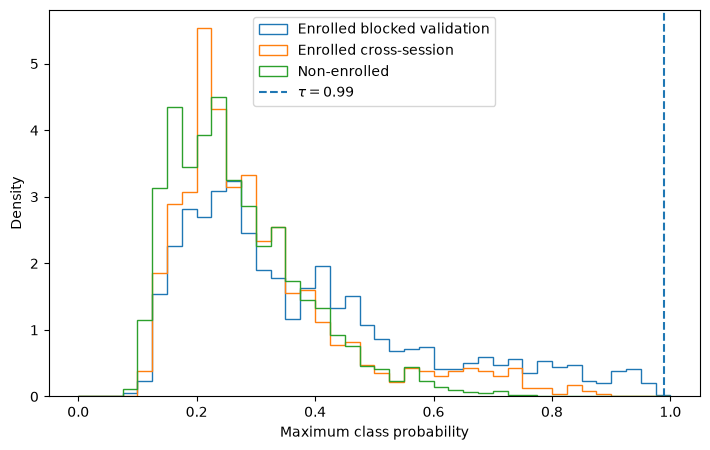

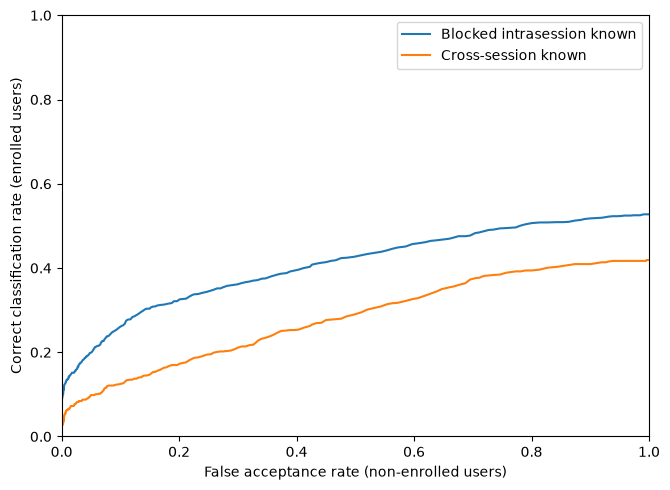

In [16]:
seed42_blocked = (
    fixed_open_details[42]["blocked"]
)

seed42_later = (
    fixed_open_details[42]["later"]
)

fig, ax = plt.subplots(
    figsize=(7.2, 4.6)
)

bins = np.linspace(
    0.0,
    1.0,
    41,
)

ax.hist(
    seed42_blocked["known_scores"],
    bins=bins,
    density=True,
    histtype="step",
    label="Enrolled blocked validation",
)

ax.hist(
    seed42_later["known_scores"],
    bins=bins,
    density=True,
    histtype="step",
    label="Enrolled cross-session",
)

ax.hist(
    seed42_blocked["unknown_scores"],
    bins=bins,
    density=True,
    histtype="step",
    label="Non-enrolled",
)

ax.axvline(
    0.99,
    linestyle="--",
    label=r"$\tau=0.99$",
)

ax.set_xlabel(
    "Maximum class probability"
)

ax.set_ylabel(
    "Density"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "confidence_distribution_blocked_baseline.pdf",
    bbox_inches="tight",
)

plt.show()


fig, ax = plt.subplots(
    figsize=(6.8, 5.0)
)

ax.plot(
    seed42_blocked["far"],
    seed42_blocked["ccr"],
    label="Blocked intrasession known",
)

ax.plot(
    seed42_later["far"],
    seed42_later["ccr"],
    label="Cross-session known",
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel(
    "False acceptance rate (non-enrolled users)"
)

ax.set_ylabel(
    "Correct classification rate (enrolled users)"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "oscr_curve_blocked_baseline.pdf",
    bbox_inches="tight",
)

plt.show()

## Open-set identity-partition sensitivity

In [17]:
def prepare_partition(
    enrolled_users,
    unknown_users,
):
    enrolled_mask_local = (
        meta_dev_all["UserID"]
        .isin(enrolled_users)
        .to_numpy()
    )

    unknown_mask_local = (
        meta_dev_all["UserID"]
        .isin(unknown_users)
        .to_numpy()
    )

    train_idx, val_idx = (
        chronological_block_indices(
            meta_dev_all,
            enrolled_mask_local,
        )
    )

    X_dev_flat = select_flatten(
        X_dev_all,
        ALL_FEATURES,
    )

    X_later_flat = select_flatten(
        X_later_all,
        ALL_FEATURES,
    )

    X_train = X_dev_flat[
        train_idx
    ]

    mean, std = fit_standardizer(
        X_train
    )

    return {
        "X_train":
            apply_standardizer(
                X_train,
                mean,
                std,
            ),
        "X_val":
            apply_standardizer(
                X_dev_flat[val_idx],
                mean,
                std,
            ),
        "X_unknown":
            apply_standardizer(
                X_dev_flat[unknown_mask_local],
                mean,
                std,
            ),
        "X_later":
            apply_standardizer(
                X_later_flat,
                mean,
                std,
            ),
        "y_train":
            y_dev[train_idx],
        "y_val":
            y_dev[val_idx],
        "y_unknown":
            y_dev[unknown_mask_local],
        "y_later":
            y_later,
    }


all_users = np.array(
    sorted(
        meta_dev_all["UserID"]
        .unique()
        .tolist()
    ),
    dtype=int,
)

candidate_unknown = np.array(
    [
        u
        for u in all_users
        if u not in RETURNING_USERS
    ],
    dtype=int,
)

partition_rows = []

for partition_seed in PARTITION_SEEDS:
    rng = np.random.default_rng(
        partition_seed
    )

    unknown_users = np.sort(
        rng.choice(
            candidate_unknown,
            size=15,
            replace=False,
        )
    )

    unknown_set = set(
        unknown_users.tolist()
    )

    enrolled_users = np.array(
        [
            u
            for u in all_users
            if u not in unknown_set
        ],
        dtype=int,
    )

    assert len(enrolled_users) == 40
    assert len(unknown_users) == 15
    assert set(RETURNING_USERS).issubset(
        set(enrolled_users)
    )

    p = prepare_partition(
        enrolled_users,
        unknown_users,
    )

    model = make_extratrees(
        42
    )

    model.fit(
        p["X_train"],
        p["y_train"],
    )

    blocked = open_set_metrics(
        model,
        p["X_val"],
        p["y_val"],
        p["X_unknown"],
    )

    later = open_set_metrics(
        model,
        p["X_later"],
        p["y_later"],
        p["X_unknown"],
    )

    partition_rows.extend([
        {
            "PartitionSeed":
                partition_seed,
            "KnownSet":
                "Blocked intrasession",
            "UnknownUsers":
                ",".join(
                    map(
                        str,
                        unknown_users.tolist(),
                    )
                ),
            "AUROC":
                blocked["AUROC"],
            "EER":
                blocked["EER"],
            "CCR_at_5pct_FAR":
                blocked["CCR_at_5pct_FAR"],
            "CCR_at_1pct_FAR":
                blocked["CCR_at_1pct_FAR"],
        },
        {
            "PartitionSeed":
                partition_seed,
            "KnownSet":
                "Cross-session",
            "UnknownUsers":
                ",".join(
                    map(
                        str,
                        unknown_users.tolist(),
                    )
                ),
            "AUROC":
                later["AUROC"],
            "EER":
                later["EER"],
            "CCR_at_5pct_FAR":
                later["CCR_at_5pct_FAR"],
            "CCR_at_1pct_FAR":
                later["CCR_at_1pct_FAR"],
        },
    ])


partition_runs = pd.DataFrame(
    partition_rows
)

partition_summary = (
    partition_runs
    .groupby(
        "KnownSet",
        sort=False,
    )
    .agg(
        AUROC_mean=(
            "AUROC",
            "mean",
        ),
        AUROC_sd=(
            "AUROC",
            "std",
        ),
        EER_mean=(
            "EER",
            "mean",
        ),
        EER_sd=(
            "EER",
            "std",
        ),
        CCR5_mean=(
            "CCR_at_5pct_FAR",
            "mean",
        ),
        CCR5_sd=(
            "CCR_at_5pct_FAR",
            "std",
        ),
        CCR1_mean=(
            "CCR_at_1pct_FAR",
            "mean",
        ),
        CCR1_sd=(
            "CCR_at_1pct_FAR",
            "std",
        ),
    )
    .reset_index()
)

partition_display = (
    partition_summary.copy()
)

for c in [
    "EER_mean",
    "EER_sd",
    "CCR5_mean",
    "CCR5_sd",
    "CCR1_mean",
    "CCR1_sd",
]:
    partition_display[c] = (
        100 * partition_display[c]
    )

display(
    partition_display.round(3)
)

partition_runs.to_csv(
    OUTPUT_DIR / "open_set_partition_sensitivity_runs.csv",
    index=False,
)

partition_summary.to_csv(
    OUTPUT_DIR / "open_set_partition_sensitivity_summary.csv",
    index=False,
)

,KnownSet,AUROC_mean,AUROC_sd,EER_mean,EER_sd,CCR5_mean,CCR5_sd,CCR1_mean,CCR1_sd
0,Blocked intrasession,0.661,0.023,38.650,1.770,18.882,3.239,10.151,2.059
1,Cross-session,0.609,0.030,43.509,2.624,10.454,1.674,5.335,1.838


## Output files

In [18]:
generated_files = sorted([
    str(p)
    for p in OUTPUT_DIR.rglob("*")
    if p.is_file()
])

for path in generated_files:
    print(path)

analysis_outputs\algorithm_ari_matrix.csv
analysis_outputs\algorithm_assignment_agreement.csv
analysis_outputs\algorithm_assignment_agreement_matrix.csv
analysis_outputs\algorithm_consensus_dataset.csv
analysis_outputs\algorithm_consensus_summary.csv
analysis_outputs\algorithm_disagreement_by_object.csv
analysis_outputs\algorithm_disagreement_by_participant.csv
analysis_outputs\algorithm_pairwise_agreement.csv
analysis_outputs\algorithm_profile_sizes.csv
analysis_outputs\analytical_dataset_36_participants.csv
analysis_outputs\analytical_dataset_preprocessed_36_participants.csv
analysis_outputs\balanced_algorithm_comparison.csv
analysis_outputs\baseline_comparison.csv
analysis_outputs\bootstrap_diagnostic.csv
analysis_outputs\bootstrap_intervals_seed42.csv
analysis_outputs\bootstrap_practical_stability_by_representation.csv
analysis_outputs\bootstrap_stability.csv
analysis_outputs\bootstrap_stability_by_profile_representation.csv
analysis_outputs\bootstrap_stability_summary.csv
analysis